# VRDet: Stage 02/03: Features and Regime Labels

1. Build causal features from 15-minute NIFTY bars (+ India VIX, USD/INR, Brent).
2. Fit regime labelers (**HMM** primary, GMM and GARCH for comparison) on 2015–2021 only.
3. Sanity-check labels against known market shocks, inspect episodes, compare live vs hindsight decoding.
4. Save labels and the fitted HMM for the modelling stage and the app.

Code lives in `src/vrdet/`; this notebook only orchestrates and visualises.

In [ ]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = REPO / 'data' / 'processed'  # raw data: <repo>/data/raw (or set VRDET_DATA)

sys.path.insert(0, str(REPO / 'src'))
for m in [m for m in sys.modules if m == 'vrdet' or m.startswith('vrdet.')]:
    del sys.modules[m]  # forget any previously imported (stale) vrdet
OUT.mkdir(parents=True, exist_ok=True)
print('repo:', REPO)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score

from vrdet.data import load_raw
from vrdet.features import build_features, seasonal_shape
from vrdet.labels import (HMMLabeler, GMMLabeler, GARCHLabeler, STATE_NAMES,
                          event_report, regime_episodes)

pd.set_option('display.width', 200)
COLORS = {0: 'tab:green', 1: 'gold', 2: 'tab:red'}
TRAIN_END = '2021-12-31'   # labelers are fitted on data up to here only

## 1. Data validation and features
Every intraday session is checked against the official daily candles (`vrdet.quality`): a session is valid if it is
not flat, has at least 13 bars, and reproduces at least 2 of the official daily high / low / close within 1%.
Invalid NIFTY sessions are dropped; invalid India VIX sessions become missing.

In [3]:
from vrdet.quality import session_report, yearly_summary
raw = load_raw()
for name in ('NIFTY', 'INDIAVIX'):
    rep = session_report(raw[f'{name}_15m'], raw[f'{name}_1d'])
    print(f'{name} 15m: {(~rep.valid).sum()} invalid sessions')
    display(yearly_summary(rep))

NIFTY 15m: 2 invalid sessions


,sessions,valid_%,flat,partial,missing_bars,zero_range_bars,high_match_%,low_match_%,close_match_%,median_close_err_%
timestamp,,,,,,,,,,
2015,244,100.0,0,0,0,0,99.6,99.6,99.6,0.000
2016,246,100.0,0,0,0,0,100.0,100.0,100.0,0.000
2017,247,100.0,0,0,47,0,95.1,95.1,95.1,0.000
2018,245,100.0,0,0,13,0,100.0,100.0,100.0,0.000
2019,244,100.0,0,0,0,0,100.0,100.0,100.0,0.000
2020,250,100.0,0,0,31,1,99.6,100.0,100.0,0.000
2021,247,99.6,0,1,21,0,99.6,100.0,99.6,0.000
2022,247,100.0,0,0,0,1,100.0,100.0,100.0,0.000
2023,245,100.0,0,0,0,0,100.0,100.0,100.0,0.000


INDIAVIX 15m: 207 invalid sessions


,sessions,valid_%,flat,partial,missing_bars,zero_range_bars,high_match_%,low_match_%,close_match_%,median_close_err_%
timestamp,,,,,,,,,,
2015,22,0.0,21,0,0,459,0.0,0.0,0.0,99.008
2016,246,27.6,161,0,0,3349,29.3,27.6,28.0,98.989
2017,247,99.6,0,1,14,0,100.0,88.7,100.0,0.000
2018,245,100.0,0,0,2,0,100.0,97.1,99.6,0.000
2019,244,100.0,0,0,1,0,100.0,98.8,96.3,0.000
2020,250,99.6,0,0,8,2,99.6,99.6,100.0,0.000
2021,245,99.2,0,1,28,17,99.6,98.0,98.8,0.000
2022,247,99.2,0,0,11,0,99.2,93.9,100.0,0.000
2023,245,100.0,0,0,3,0,100.0,100.0,95.9,0.000


In [4]:
nifty, vix = raw['NIFTY_15m'], raw['INDIAVIX_15m']
daily = {'usdinr': raw['USDINR_1d'], 'brent': raw['BRENT_1d']}

f = build_features(nifty, vix, daily, nifty_daily=raw['NIFTY_1d'], vix_daily=raw['INDIAVIX_1d'])
print(f.shape, f.index[0], '->', f.index[-1])
f.describe().T[['count', 'mean', 'std', 'min', 'max']].round(4)

(72634, 40) 2015-01-01 09:15:00+05:30 -> 2026-10-29 15:15:00+05:30


,count,mean,std,min,max
ret,72601.0,-0.0000,0.0015,-0.0546,0.0619
gap,72609.0,0.0011,0.0064,-0.0959,0.0478
z,72101.0,-0.0000,0.0015,-0.0240,0.0732
range_ds,72083.0,0.0019,0.0014,0.0002,0.0671
rv_4,72108.0,9.1615,7.6356,0.0959,417.3520
pk_4,72132.0,9.5128,6.2112,2.0240,270.4102
gk_4,72132.0,9.5336,5.9341,2.2693,233.2998
rv_8,72104.0,9.5530,7.0849,0.8470,278.8213
pk_8,72129.0,9.6535,5.9721,2.6876,196.9211
gk_8,72129.0,9.6512,5.7331,2.8874,174.4046


### Intraday seasonality
Raw 15-minute volatility is U-shaped across the session. Without removing it, a regime model would simply learn
"09:15 = Chaotic, 12:30 = Quiet". `z` and `range_ds` divide by a causal time-of-day profile.

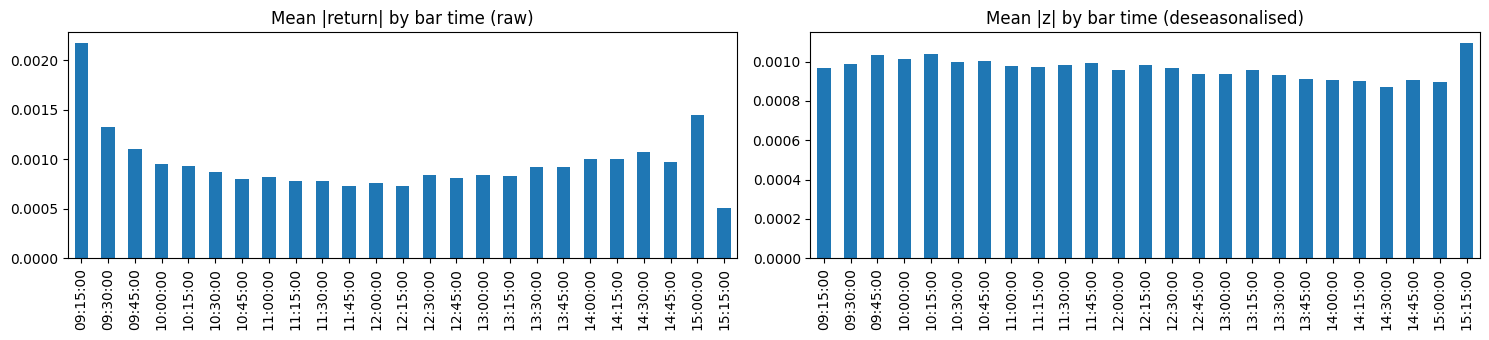

In [5]:
r = f['ret']
fig, ax = plt.subplots(1, 2, figsize=(15, 3.5))
r.abs().groupby(r.index.time).mean().plot(kind='bar', ax=ax[0], title='Mean |return| by bar time (raw)')
f['z'].abs().groupby(f.index.time).mean().plot(kind='bar', ax=ax[1], title='Mean |z| by bar time (deseasonalised)')
plt.tight_layout(); plt.show()

## 2. HMM labeler (primary)
3-state Gaussian HMM (`hmmlearn`, diagonal covariance) on `[z, log range_ds]` (standardised), with a sticky
Dirichlet prior on self-transitions, states ordered by volatility, and a minimum regime length of 4 bars (1 hour).
Fitted on 2015–2021; decoded over the full history.

- **Hindsight labels** = Viterbi path (`hmmlearn` `predict`); uses the whole sequence, so it is the *target*.
- **Live labels** = forward-filtered probabilities P(state_t | data up to t) (Rabiner, 1989). `hmmlearn` only
  provides smoothed probabilities (which use future bars), so the filter is a short function in `vrdet.labels`.

In [6]:
hmm_lab = HMMLabeler().fit(f, end=TRAIN_END)
import hmmlearn
print('hmmlearn', hmmlearn.__version__, '| log-likelihood:', round(hmm_lab.loglik_, 1))
display(hmm_lab.summary())
pd.DataFrame(hmm_lab.transmat_, index=STATE_NAMES, columns=STATE_NAMES).round(4)

hmmlearn 0.3.3 | log-likelihood: -93590.3


,z_sd,range_ds_typical,expected_duration_bars
Quiet,0.000660,0.001147,20.080690
Normal,0.001337,0.002059,15.216208
Chaotic,0.003841,0.004230,25.521234


,Quiet,Normal,Chaotic
Quiet,0.9502,0.0465,0.0033
Normal,0.0504,0.9343,0.0153
Chaotic,0.0004,0.0388,0.9608


In [7]:
labels = hmm_lab.hindsight(f)            # target: hindsight (Viterbi) labels
live = hmm_lab.live(f)                   # benchmark: real-time filtered labels
p_live = hmm_lab.filtered_proba(f)

print('Regime share (hindsight):')
print(labels.map(dict(enumerate(STATE_NAMES))).value_counts(normalize=True).round(3))

Regime share (hindsight):
regime
Quiet      0.494
Normal     0.432
Chaotic    0.074
Name: proportion, dtype: float64


### Sanity check: known market shocks should be Chaotic

In [8]:
event_report(labels)

,event,Quiet,Normal,Chaotic
date,,,,
2015-08-24,"China devaluation crash (""Black Monday"")",0.0,0.16,0.84
2016-06-24,Brexit referendum result,0.0,0.40,0.60
2016-11-09,Demonetisation + US election result,0.0,0.00,1.00
2018-09-21,IL&FS / DHFL intraday crash,0.0,0.52,0.48
2020-03-12,COVID: WHO pandemic declaration sell-off,0.0,0.00,1.00
2020-03-23,"COVID: lower circuit, lockdown",0.0,0.00,1.00
2021-02-01,Union Budget rally,0.0,0.00,1.00
2022-02-24,Russia invades Ukraine,0.0,0.00,1.00
2024-06-04,General election results,0.0,0.00,1.00


### Regimes over time

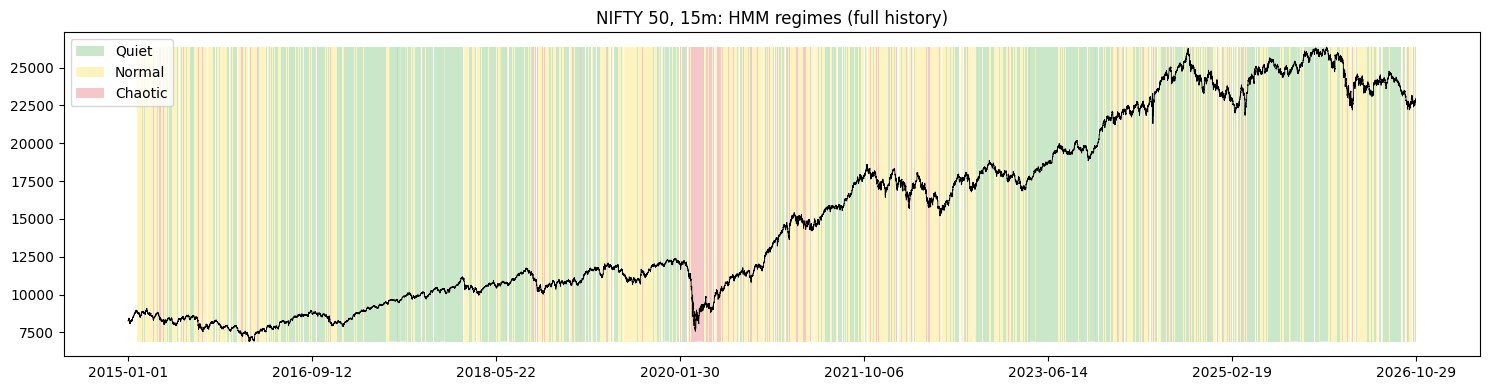

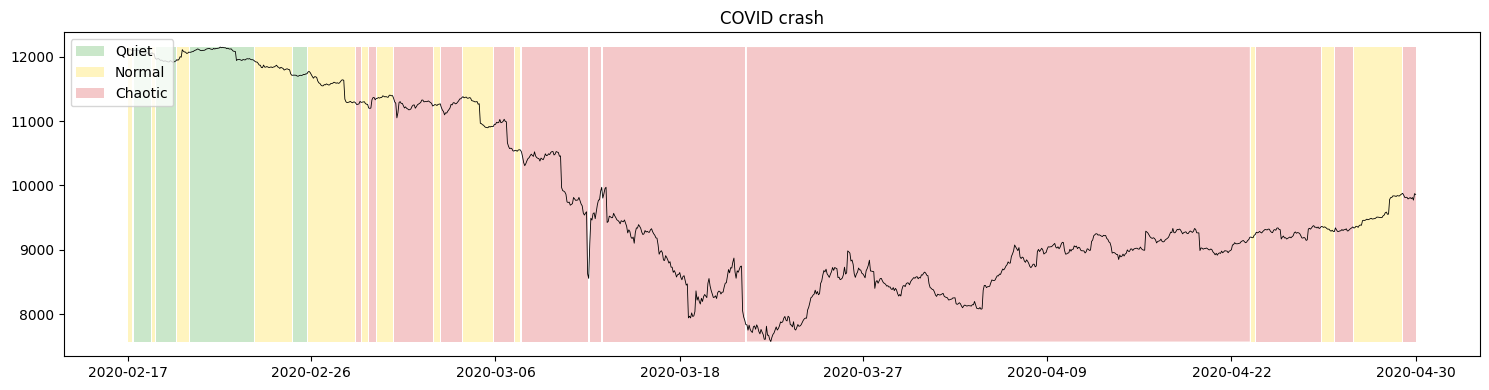

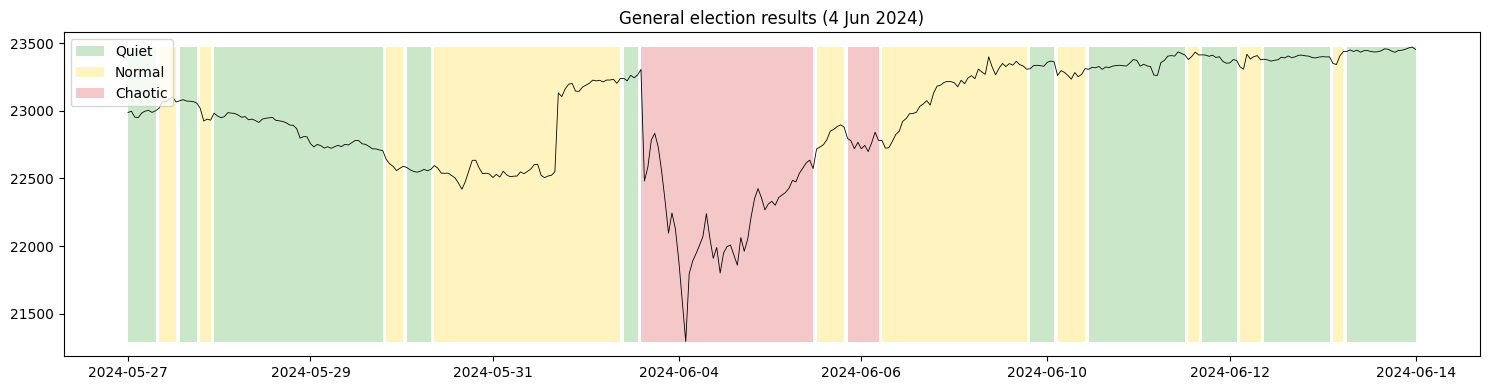

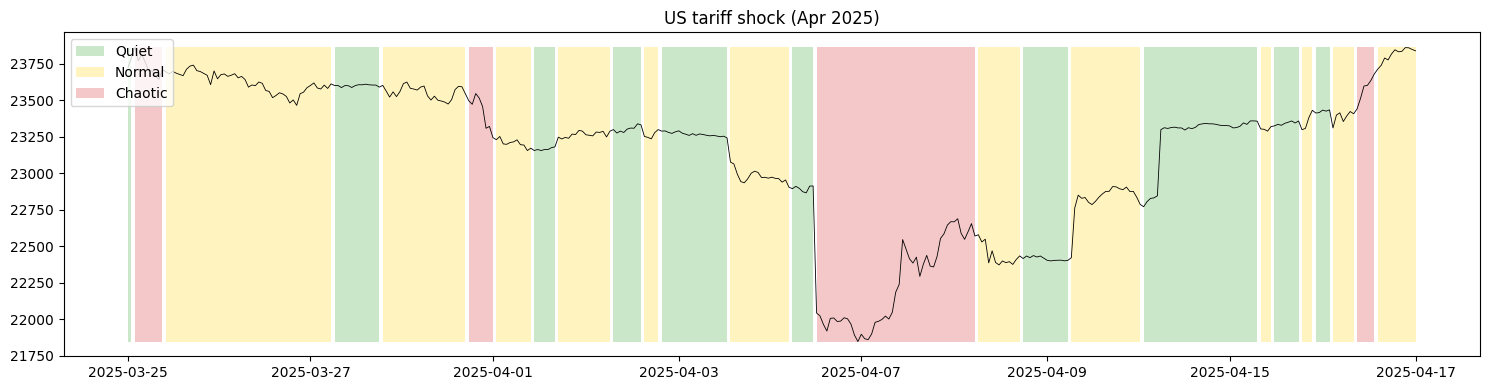

In [9]:
def plot_regimes(start=None, end=None, title=''):
    c = nifty['close'].loc[start:end]
    lab = labels.reindex(c.index)
    x = np.arange(len(c))  # bar index -> no overnight/weekend gaps
    fig, ax = plt.subplots(figsize=(15, 4))
    ax.plot(x, c.to_numpy(), color='black', lw=0.6)
    lo, hi = c.min(), c.max()
    for k, col in COLORS.items():
        ax.fill_between(x, lo, hi, where=(lab == k).to_numpy(), color=col, alpha=0.25, step='mid', lw=0,
                        label=STATE_NAMES[k])
    ticks = np.linspace(0, len(c) - 1, 8).astype(int)
    ax.set_xticks(ticks, [c.index[i].strftime('%Y-%m-%d') for i in ticks])
    ax.set_title(title); ax.legend(loc='upper left'); plt.tight_layout(); plt.show()

plot_regimes(title='NIFTY 50, 15m: HMM regimes (full history)')
plot_regimes('2020-02-15', '2020-04-30', 'COVID crash')
plot_regimes('2024-05-27', '2024-06-14', 'General election results (4 Jun 2024)')
plot_regimes('2025-03-25', '2025-04-20', 'US tariff shock (Apr 2025)')

### Chaotic episodes

342 Chaotic episodes; length (hours):
count    342.00
mean       3.89
std        9.56
min        0.25
25%        1.25
50%        2.12
75%        3.75
max      167.50
Name: hours, dtype: float64


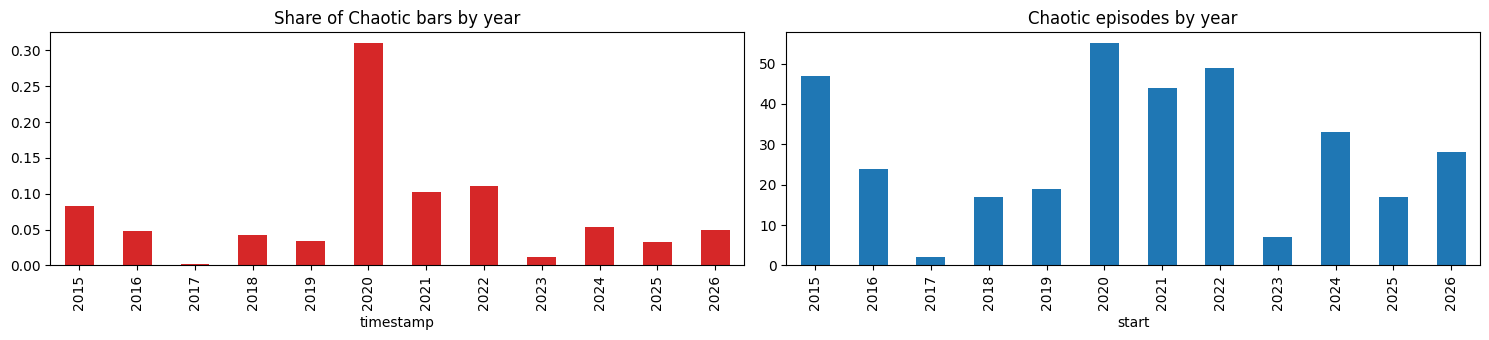

,start,end,n_bars,hours
116,2020-03-09 12:30:00+05:30,2020-04-22 14:30:00+05:30,670,167.50
132,2020-06-11 10:30:00+05:30,2020-06-17 14:45:00+05:30,102,25.50
124,2020-05-15 14:00:00+05:30,2020-05-20 14:45:00+05:30,79,19.75
182,2021-03-18 12:45:00+05:30,2021-03-23 11:45:00+05:30,72,18.00
34,2015-08-24 10:15:00+05:30,2015-08-27 09:15:00+05:30,72,18.00
120,2020-05-04 14:45:00+05:30,2020-05-07 13:30:00+05:30,71,17.75
169,2021-01-29 09:30:00+05:30,2021-02-02 13:45:00+05:30,68,17.00
167,2021-01-21 14:45:00+05:30,2021-01-27 11:45:00+05:30,64,16.00
131,2020-06-08 12:15:00+05:30,2020-06-10 15:15:00+05:30,63,15.75
134,2020-06-24 10:30:00+05:30,2020-06-26 13:30:00+05:30,63,15.75


In [10]:
ep = regime_episodes(labels, state=2)
ep['hours'] = ep['n_bars'] / 4
print(f'{len(ep)} Chaotic episodes; length (hours):')
print(ep['hours'].describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 3.5))
(labels == 2).groupby(labels.index.year).mean().plot(kind='bar', ax=ax[0], color='tab:red',
                                                     title='Share of Chaotic bars by year')
ep.groupby(ep['start'].dt.year).size().plot(kind='bar', ax=ax[1], title='Chaotic episodes by year')
plt.tight_layout(); plt.show()
ep.sort_values('n_bars', ascending=False).head(10)

### Live (filtered) vs hindsight labels
The live HMM filter is what can be computed in real time. This is the key benchmark the ML classifiers must beat
(formal metrics in Stage 04).

In [11]:
idx = labels.index
ct = pd.crosstab(labels.map(dict(enumerate(STATE_NAMES))).rename('hindsight'),
                 live.reindex(idx).map(dict(enumerate(STATE_NAMES))).rename('live'), normalize='index').round(3)
print('agreement:', round((labels == live.reindex(idx)).mean(), 3))
ct

agreement: 0.85


live,Chaotic,Normal,Quiet
hindsight,,,
Chaotic,0.844,0.156,0.001
Normal,0.062,0.833,0.105
Quiet,0.005,0.129,0.866


## 3. Alternative labelers: GMM and GARCH
Same training span. GMM ignores time ordering; GARCH bins one-step-ahead conditional volatility
(30th / 94th training percentiles).

In [12]:
others = {'GMM': GMMLabeler().fit(f, end=TRAIN_END), 'GARCH': GARCHLabeler().fit(f, end=TRAIN_END)}
all_labels = {'HMM': labels, **{k: v.hindsight(f) for k, v in others.items()}}
all_live = {'HMM': live, **{k: v.live(f) for k, v in others.items()}}

rows = []
for name, lab in all_labels.items():
    ev = event_report(lab)
    rows.append({'labeler': name,
                 **{s: round((lab == k).mean(), 3) for k, s in enumerate(STATE_NAMES)},
                 'chaotic_episodes': len(regime_episodes(lab)),
                 'event_chaotic_mean': round(ev['Chaotic'].mean(), 2),
                 'event_chaotic_min': round(ev['Chaotic'].min(), 2),
                 'live_vs_hindsight': round((lab == all_live[name].reindex(lab.index)).mean(), 3)})
display(pd.DataFrame(rows).set_index('labeler'))

common = all_labels['HMM'].index.intersection(all_labels['GARCH'].index)
names = list(all_labels)
kappa = pd.DataFrame([[cohen_kappa_score(all_labels[a].reindex(common), all_labels[b].reindex(common))
                       for b in names] for a in names], index=names, columns=names).round(3)
kappa

,Quiet,Normal,Chaotic,chaotic_episodes,event_chaotic_mean,event_chaotic_min,live_vs_hindsight
labeler,,,,,,,
HMM,0.494,0.432,0.074,342,0.89,0.48,0.850
GMM,0.701,0.280,0.019,61,0.53,0.00,0.748
GARCH,0.317,0.634,0.049,150,0.68,0.00,0.980


,HMM,GMM,GARCH
HMM,1.000,0.498,0.506
GMM,0.498,1.000,0.302
GARCH,0.506,0.302,1.000


**Reading the comparison**
- *event_chaotic_mean*: share of bars labelled Chaotic on known shock sessions; higher is better.
- *live_vs_hindsight*: if close to 1, the labeler's real-time output already equals its target, so there is nothing
  for a classifier to learn (GARCH). If too low, the target is unreachable in real time.
- The HMM is the primary target; GMM/GARCH labels are kept for robustness checks.

## 4. Save

In [13]:
out = f.join(labels.rename('regime')).join(live.rename('regime_live_hmm'))
out = out.join(p_live.add_prefix('p_live_'))
for k, v in all_labels.items():
    if k != 'HMM':
        out[f'regime_{k.lower()}'] = v
out.to_parquet(OUT / 'features_labels_15m.parquet')

(REPO / 'models').mkdir(exist_ok=True)
(REPO / 'models' / 'hmm_labeler.json').write_text(hmm_lab.to_json())
print('saved', OUT / 'features_labels_15m.parquet', out.shape, '| models/hmm_labeler.json')

saved /content/vrdet_data/processed/features_labels_15m.parquet (72634, 47) | models/hmm_labeler.json
